# Wprowadzenie: funkcje kosztu i optymalizatory


**Plan:**
1. Jak matematycznie opisać „dobrą predykcję”? Trzy geometryczne funkcje kosztu, minima i obserwacje odstające.
2. Jak minimalizować koszt za pomocą gradientu? Także wtedy, gdy minimum nie daje się łatwo policzyć analitycznie.
3. Jak działa prosta sieć neuronowa, `CrossEntropyLoss` i propagacja wsteczna?
4. Jak tę samą funkcję optymalizują SGD, Momentum, AdaGrad, RMSProp i Adam?
5. Jak połączyć cały proces i rozsądnie interpretować wyniki?

**Wymagania:** `numpy`, `matplotlib`, `torch`. Wszystkie potrzebne paczki znajdują się w środowisku z udostępnionego `ml_requirements.txt`.

## Jak korzystać z tego notebooka?

Ten materiał jest **przewodnikiem po procesie uczenia**, a nie zbiorem rozwiązanych zadań. Czytaj komórki po kolei: definicja i intuicja są przed implementacją, a wykresy mają służyć sprawdzeniu przewidywań. Możesz zmieniać parametry kodu i ponownie uruchamiać eksperymenty.

**Po ukończeniu** powinieneś umieć wyjaśnić: (1) dlaczego wybór straty zmienia rozwiązanie, (2) skąd bierze się gradient, (3) czym są logity i cross-entropy, (4) jak `backward()` oblicza pochodne, (5) czym różnią się aktualizacje SGD, Momentum, AdaGrad, RMSProp i Adam.

### Jedna mapa pojęć

Dane $(x,y)$ -> **model** $f_\theta(x)$ -> predykcja -> **funkcja straty** $L(\theta)$ -> **gradient** $\nabla_\theta L$ -> **optymalizator** -> nowe parametry $\theta$. Następnie powtarzamy obliczenia. Osobno mierzymy jakość na danych testowych.

W przykładzie geometrycznym model ma tylko parametr $v$; w sieci neuronowej parametrami są macierze wag i wektory przesunięć. Mechanizm minimalizacji pozostaje taki sam.

**Notacja:** $N$ – liczba obserwacji, $B$ – liczba przykładów w paczce (batch), $C$ – liczba klas, $\eta$ – współczynnik uczenia (learning rate), $\theta$ – zbiór parametrów.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

np.random.seed(67)
torch.manual_seed(67)
plt.rcParams["figure.figsize"] = (7, 4)

# Jednolity język wizualny: kolor ma to samo znaczenie w całym materiale.
COL = {
    "blue": "#2563EB",
    "orange": "#F59E0B",
    "green": "#059669",
    "red": "#DC2626",
    "purple": "#7C3AED",
    "ink": "#17253B",
    "muted": "#64748B",
}
OPT_COL = {
    "GD": COL["blue"],
    "SGD": COL["blue"],
    "Momentum": COL["orange"],
    "AdaGrad": COL["green"],
    "RMSProp": COL["purple"],
    "Adam": COL["red"],
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 4.8),
        "figure.dpi": 115,
        "savefig.dpi": 150,
        "font.size": 10.5,
        "axes.titlesize": 12.5,
        "axes.titleweight": "semibold",
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#CBD5E1",
        "axes.labelcolor": COL["ink"],
        "text.color": COL["ink"],
        "xtick.color": COL["muted"],
        "ytick.color": COL["muted"],
        "grid.color": "#E2E8F0",
        "grid.alpha": 0.8,
        "lines.linewidth": 2.2,
        "legend.frameon": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)


def style_axes(ax, grid=True):
    if grid:
        ax.grid(True, alpha=0.55, zorder=0)
    ax.set_axisbelow(True)
    return ax

## 1. Geometria funkcji kosztu

Szukamy **jednego punktu** $v\in\mathbb R^d$, który najlepiej reprezentuje zbiór $X=\{x_1,\ldots,x_N\}$. To prosty problem uczenia parametrów: wybór *funkcji kosztu* określa, co oznacza „najlepiej”.

Rozważamy trzy kryteria:

- `mean_error` = średnia odległość euklidesowa: $L_{ME}(v)=\frac1N\sum_i\|x_i-v\|_2$;
- `mean_squared_error` = średnia **kwadratów odległości**: $L_{MSE}(v)=\frac1N\sum_i\|x_i-v\|_2^2$;
- `max_error` = największa odległość: $L_{max}(v)=\max_i\|x_i-v\|_2$.

Dla $d=1$ `mean_error` odpowiada MAE (Mean Absolute Error). Dla $d>1$ jest średnią normą euklidesową, a nie średnią po współrzędnych.

### Co właściwie minimalizujemy?

Wyobraźmy sobie, że chcemy wybrać jeden punkt jako reprezentanta wielu pomiarów. Nie istnieje jedna odpowiedź na pytanie „który punkt jest najlepszy”, dopóki nie ustalimy **jak mierzymy błąd**. Średnia odległość traktuje błąd 2 jako dwa razy większy od błędu 1; kwadrat odległości traktuje go jako cztery razy bardziej kosztowny. Maksymalna odległość skupia się na najgorszym przypadku.

**Nie myl trzech znaczeń:** *model* określa co można przewidywać; *funkcja straty* określa co uznajemy za dobry wynik; *optymalizator* szuka parametrów dających niski koszt.

W pierwszym eksperymencie zobaczymy tę różnicę bez sieci neuronowej, aby nic nie zasłaniało geometrii problemu.

In [41]:
train_set_1d = np.random.uniform(-5, 5, size=(15, 1))
train_set_2d = np.random.normal(-1, 3, size=(13, 2))
train_set_10d = np.random.exponential(2, size=(31, 10))
for name, data in [("1D", train_set_1d), ("2D", train_set_2d), ("10D", train_set_10d)]:
    print(name, "kształt:", data.shape, ", pierwszy punkt:", np.round(data[0], 2))

1D kształt: (15, 1) , pierwszy punkt: [0.46]
2D kształt: (13, 2) , pierwszy punkt: [-4.83 -3.36]
10D kształt: (31, 10) , pierwszy punkt: [0.73 0.3  7.39 0.02 4.5  0.87 5.24 1.02 1.26 1.19]


In [42]:
def mean_error(X, v):
    return float(np.linalg.norm(X - np.asarray(v), axis=1).mean())


def mean_squared_error(X, v):
    return float(np.square(X - np.asarray(v)).sum(axis=1).mean())


def max_error(X, v):
    return float(np.linalg.norm(X - np.asarray(v), axis=1).max())


X = np.array([[0.0], [1.0], [2.0], [9.0]])
for fn in [mean_error, mean_squared_error, max_error]:
    print(f"{fn.__name__:>20}: {fn(X, np.array([1.])):.3f}")

          mean_error: 2.500
  mean_squared_error: 16.500
           max_error: 8.000


**Dlaczego w ogóle trzy nazwy?** Dla danych jednowymiarowych minimalizacja $\sum_i (x_i-v)^2$ daje średnią (różniczkujemy i przyrównujemy pochodną do zera). Minimalizacja $\sum_i|x_i-v|$ daje dowolną medianę (po obu stronach mediany liczba punktów się równoważy). Minimalizację $\max_i|x_i-v|$ osiąga **środek przedziału od minimum do maksimum**: $(x_{\min}+x_{\max})/2$ – redukujemy w ten sposób najgorszą odległość. W wielu wymiarach interpretacja wymaga już mediany geometrycznej lub środka najmniejszej kuli obejmującej punkty.

**Przewidywanie przed kodem:** jeśli do danych dodamy bardzo duży pojedynczy pomiar, która z tych trzech lokalizacji przesunie się najbardziej? Czy mediana pozostanie taka sama?

### 1.1. Jeden zbiór, trzy różne minima

W 1D minimum ME osiąga **mediana**, MSE **średnia arytmetyczna**, a maksimum odległości **środek między najmniejszą i największą obserwacją**. Dla wyższych wymiarów te proste wzory nie przenoszą się wprost: np. minimum średniej odległości euklidesowej to *mediana geometryczna*, nie mediana liczona niezależnie po współrzędnych.

To ważny przykład: **algorytm optymalizacji** nie określa, co jest poprawnym wynikiem; robi to **funkcja kosztu**.

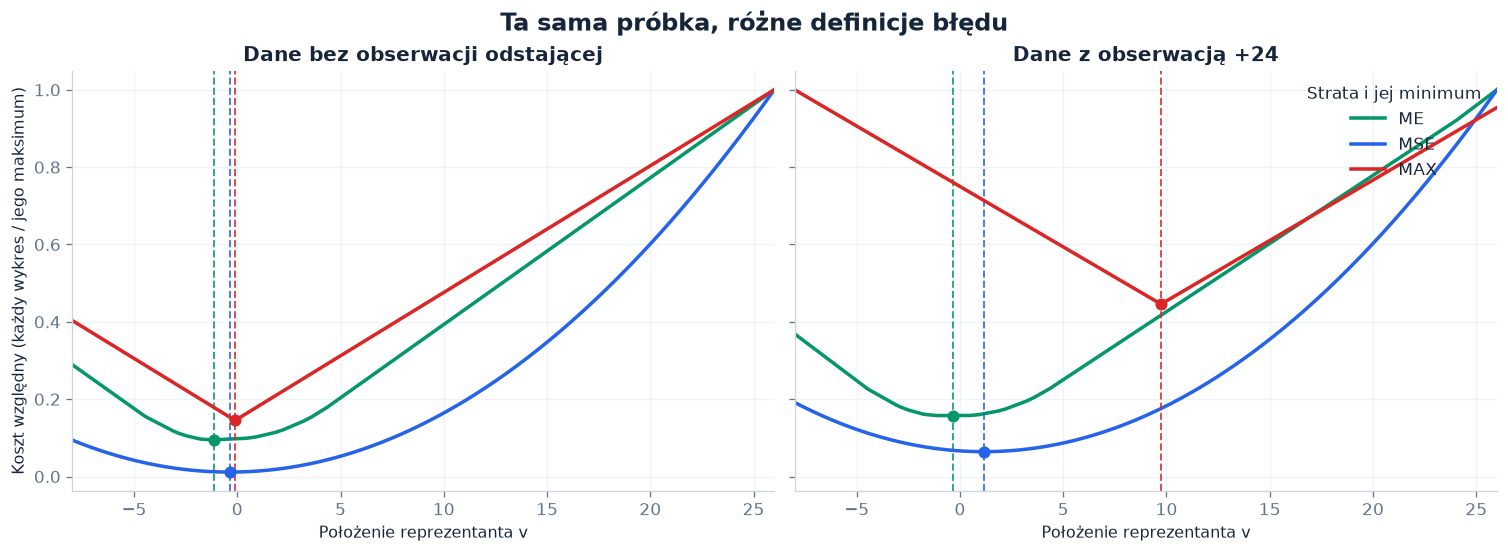

Przed {'ME': -1.14, 'MSE': -0.37, 'MAX': -0.1}
Po {'ME': -0.34, 'MSE': 1.16, 'MAX': 9.73}


In [43]:
def optimum_1d(X, which):
    x = np.asarray(X).reshape(-1)
    return {"ME": np.median(x), "MSE": np.mean(x), "MAX": (x.min() + x.max()) / 2}[
        which
    ]


X1 = train_set_1d.copy()
X_outlier = np.vstack([X1, [[24.0]]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), sharey=True, layout="constrained")
colors = {"ME": COL["green"], "MSE": COL["blue"], "MAX": COL["red"]}
for ax, (label, data) in zip(
    axes, [("Dane bez obserwacji odstającej", X1), ("Dane z obserwacją +24", X_outlier)]
):
    grid = np.linspace(-8, 26, 450)
    for key, fn in [
        ("ME", mean_error),
        ("MSE", mean_squared_error),
        ("MAX", max_error),
    ]:
        vals = np.array([fn(data, np.array([v])) for v in grid])
        vals = vals / max(vals.max(), 1e-12)
        ax.plot(grid, vals, color=colors[key], label=key)
        ax.axvline(
            optimum_1d(data, key), color=colors[key], ls="--", lw=1.2, alpha=0.85
        )
        ax.scatter(
            [optimum_1d(data, key)],
            [np.interp(optimum_1d(data, key), grid, vals)],
            color=colors[key],
            s=43,
            zorder=5,
        )
    ax.set(title=label, xlabel="Położenie reprezentanta v", xlim=(-8, 26))
    style_axes(ax)
axes[0].set_ylabel("Koszt względny (każdy wykres / jego maksimum)")
axes[1].legend(title="Strata i jej minimum", loc="upper right")
fig.suptitle("Ta sama próbka, różne definicje błędu", fontsize=15, fontweight="bold")
plt.show()
for title, data in [("Przed", X1), ("Po", X_outlier)]:
    print(
        title, {k: round(float(optimum_1d(data, k)), 2) for k in ("ME", "MSE", "MAX")}
    )

MSE silnie reaguje na odległe obserwacje, ponieważ karze błąd kwadratowo. ME często stabilniej reprezentuje „typowy” punkt. Minimax minimalizuje błąd najgorszego przypadku, więc zależy od wartości skrajnych.

Czy przypadku zadania: prognozowania zużycia energii wolelibyśmy ME, MSE czy najgorszy błąd? Dlaczego wykresy zostały osobno przeskalowane i nie wolno porównywać na ich podstawie *wartości liczbowych* strat?

### Pochodna, gradient i intuicja ruchu

W jednej zmiennej pochodna $L'(v)$ mówi, jak szybko zmieni się strata po nieznacznym zwiększeniu $v$. Dodatnia pochodna wskazuje wzrost funkcji w prawo, więc aby **zmniejszać** stratę, przesuwamy się w lewo. W wielu wymiarach analogiczną rolę pełni gradient: wektor pochodnych cząstkowych $\nabla L$ wskazuje kierunek najszybszego lokalnego wzrostu.

To wyjaśnia znak minus w aktualizacji: $v\leftarrow v-\eta\nabla L(v)$. Nie jest to ruch bezwarunkowo poprawny: gradient mówi tylko o zachowaniu **lokalnym**, a zbyt duży krok może przenieść nas za minimum.

**Uwaga o punktach niegładkich:** MAE/ME oraz funkcja maksimum mogą nie mieć zwykłej pochodnej w niektórych punktach. Można wtedy posługiwać się subgradientami; ich wybór w kodzie powinien być jawny.

### 1.2. Gradient — kierunek najszybszego wzrostu

Dla ustalonego zbioru $X$, gradient względem $v$ jest wektorem. Dla MSE:
$$\nabla_v L_{MSE}(v)=\frac2N\sum_i(v-x_i)=2(v-\bar x).$$

Dla ME, poza punktami $v=x_i$ zachodzi:
$$\nabla_v L_{ME}(v)=\frac1N\sum_i \frac{v-x_i}{\|v-x_i\|_2}.$$

Dla `max_error` używamy gradientu najdalszego punktu, **o ile jest on jedynym punktem maksymalizującym odległość**. Przy remisach i w punktach niegładkich poprawną teorią są *subgradienty*. W kodzie definiujemy bezpieczną konwencję `0` dla zerowej odległości (to jeden z możliwych subgradientów normy).

In [44]:
def mse_grad(X, v):
    return 2 * (np.asarray(v) - X.mean(axis=0))


def me_grad(X, v):
    diff = np.asarray(v) - X
    norm = np.linalg.norm(diff, axis=1, keepdims=True)
    return np.mean(
        np.divide(diff, norm, out=np.zeros_like(diff), where=norm > 1e-12), axis=0
    )


def max_grad(X, v):
    diff = np.asarray(v) - X
    d = np.linalg.norm(diff, axis=1)
    j = np.argmax(d)
    return diff[j] / d[j] if d[j] > 1e-12 else np.zeros_like(v)


point = np.array([2.0, -3.0])
print("Gradient MSE:", mse_grad(train_set_2d, point))
print("Gradient ME: ", me_grad(train_set_2d, point))
print("Gradient MAX:", max_grad(train_set_2d, point))

Gradient MSE: [ 6.71092404 -2.28847315]
Gradient ME:  [ 0.49685407 -0.19434027]
Gradient MAX: [ 0.74491092 -0.66716394]


### 1.3. Spadek gradientu krok po kroku

Podstawowa aktualizacja to $v_{t+1}=v_t-\eta \nabla L(v_t)$, gdzie $\eta$ jest *learning rate*. Duży $\eta$ może powodować oscylacje lub brak zbieżności; bardzo mały zbyt wolną naukę.

Wykorzystamy deterministyczny punkt startowy, żeby różnice na wykresach pochodziły z wyboru `learning_rate`, a nie z losowości.

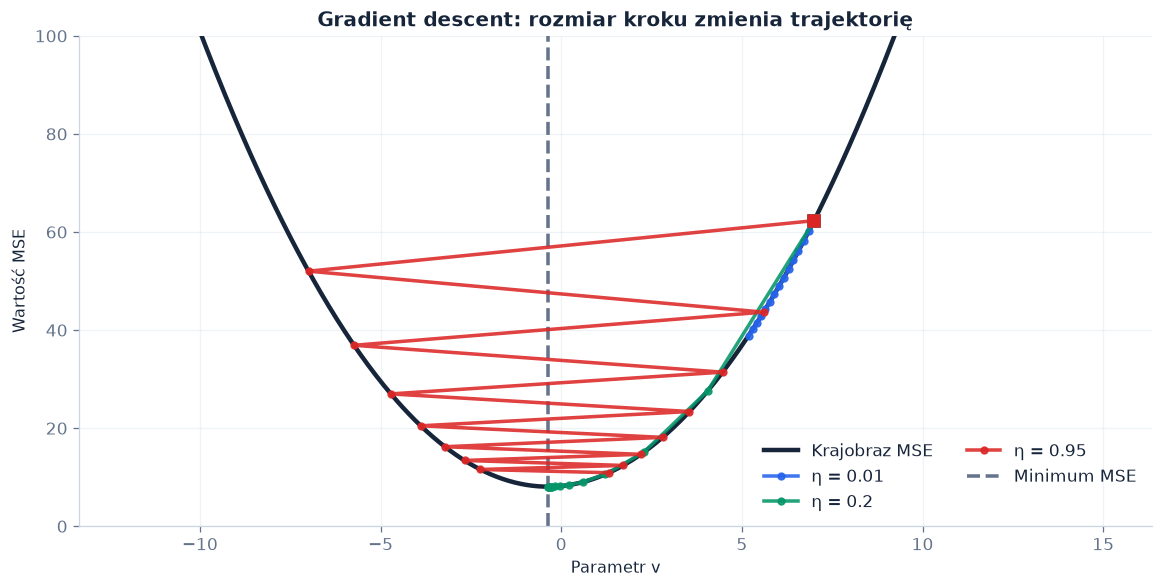

In [ ]:
def gradient_descent(grad_fn, X, initial, learning_rate=0.1, num_steps=10):
    v = np.asarray(initial, dtype=float).copy()
    path = [v.copy()]
    for _ in range(num_steps):
        v = v - learning_rate * grad_fn(X, v)
        path.append(v.copy())
    return np.asarray(path)


fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
xgrid = np.linspace(-12, 15, 500)
ygrid = [mean_squared_error(X1, [x]) for x in xgrid]
ax.plot(xgrid, ygrid, color=COL["ink"], label="Krajobraz MSE", lw=2.8, zorder=2)
for lr, color in [(0.01, COL["blue"]), (0.20, COL["green"]), (0.95, COL["red"])]:
    path = gradient_descent(mse_grad, X1, [7.0], lr, 14).ravel()
    values = [mean_squared_error(X1, [x]) for x in path]
    ax.plot(
        path, values, "-o", ms=4.2, color=color, label=f"η = {lr}", alpha=0.88, zorder=3
    )
    ax.scatter(path[0], values[0], marker="s", s=58, color=color, zorder=5)
ax.axvline(X1.mean(), color=COL["muted"], ls="--", label="Minimum MSE")
ax.set(
    xlabel="Parametr v",
    ylabel="Wartość MSE",
    title="Gradient descent: rozmiar kroku zmienia trajektorię",
    ylim=(0, 100),
)
style_axes(ax)
ax.legend(ncol=2)
plt.show()

Przy MSE w 1D pochodna jest liniowa, więc dla $0<\eta<1$ kroki dążą do optimum, a dla $\eta>1$ mogą się oddalać. Jest to szczególny przykład wynikający z naszej definicji MSE i nie stanowi uniwersalnej granicy dla innych modeli.

### 1.4. Powierzchnia straty w dwóch wymiarach

Wizualizacja w 2D pokazuje, że gradient jest wektorem i ścieżka optymalizacji przebiega po powierzchni kosztu.

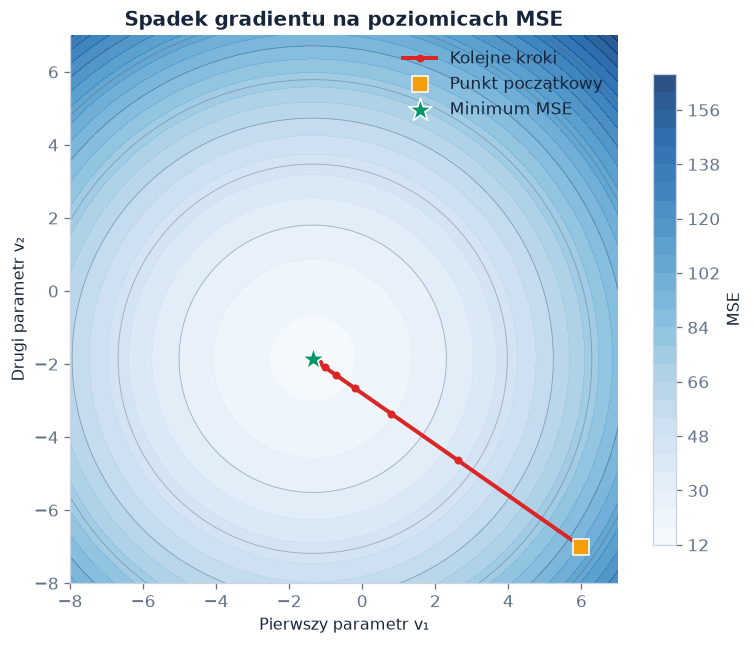

In [ ]:
xy = np.linspace(-8, 7, 130)
A, B = np.meshgrid(xy, xy)
Z = np.array(
    [mean_squared_error(train_set_2d, [a, b]) for a, b in zip(A.ravel(), B.ravel())]
).reshape(A.shape)
path2 = gradient_descent(mse_grad, train_set_2d, [6.0, -7.0], 0.23, 14)
fig, ax = plt.subplots(figsize=(7.2, 5.5), layout="constrained")
cont = ax.contourf(A, B, Z, levels=24, cmap="Blues", alpha=0.85)
ax.contour(A, B, Z, levels=12, colors="#475569", linewidths=0.55, alpha=0.38)
fig.colorbar(cont, ax=ax, label="MSE", shrink=0.86)
ax.plot(
    path2[:, 0],
    path2[:, 1],
    "o-",
    color=COL["red"],
    ms=4,
    lw=2.5,
    label="Kolejne kroki",
)
ax.scatter(
    *path2[0],
    marker="s",
    s=95,
    color=COL["orange"],
    edgecolors="white",
    zorder=5,
    label="Punkt początkowy"
)
ax.scatter(
    *train_set_2d.mean(axis=0),
    marker="*",
    s=230,
    color=COL["green"],
    edgecolors="white",
    zorder=6,
    label="Minimum MSE"
)
ax.set(
    xlabel="Pierwszy parametr v₁",
    ylabel="Drugi parametr v₂",
    title="Spadek gradientu na poziomicach MSE",
    aspect="equal",
)
ax.legend(loc="upper right")
plt.show()

### Dlaczego uczenie sieci to nadal minimalizacja funkcji?

Dotychczas przewidywaliśmy jeden reprezentatywny punkt $v$. Teraz dla każdego wejścia $x$ chcemy przewidzieć **etykietę klasy** $y$. Model ma wiele parametrów: wszystkie wagi i biasy, czyli $\theta=(W_1,b_1,W_2,b_2)$. Podstawowy schemat nie zmienia się: liczymy predykcje, stratę, jej gradient względem parametrów i krok optymalizatora.

Zbiór **dwóch koncentrycznych pierścieni** jest celowy: prostą granicą decyzyjną nie da się oddzielić środka od zewnętrznego pierścienia. Warstwa ukryta z nieliniową funkcją aktywacji może budować bardziej złożoną granicę.

**Dwie osobne kwestie:** architektura decyduje, jakie zależności da się opisać; trening decyduje, czy znajdziemy odpowiednie wagi.

## 2. Od prostej funkcji do sieci neuronowej

Model liniowy $f(x)=Wx+b$ wyznacza liniową granicę decyzji. Aby reprezentować bardziej złożone zależności, składamy warstwy liniowe:
$$h=\tanh(W_1 x+b_1),\qquad z=W_2 h+b_2.$$

$z$ to **logity**, nie prawdopodobieństwa. W klasyfikacji wieloklasowej `CrossEntropyLoss` przyjmuje logity i indeksy klas; wewnątrz wykonuje stabilne numerycznie operacje odpowiadające `log_softmax` i NLL (negative log likelihood). Nie należy wcześniej stosować `softmax` do logitów podawanych do tej funkcji.

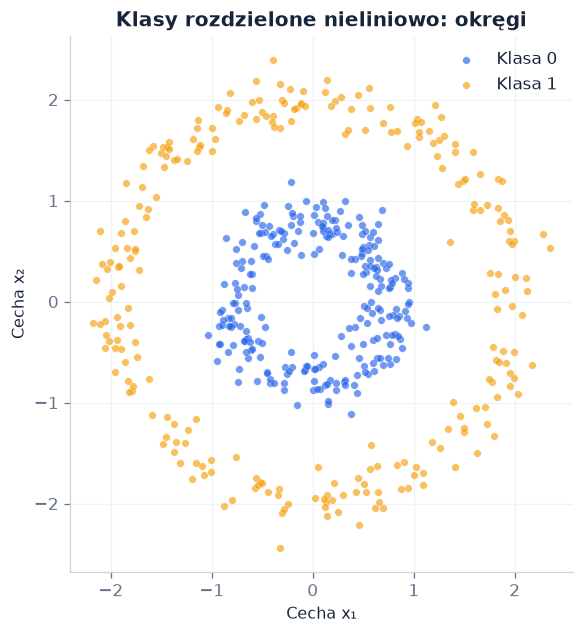

In [ ]:
rng = np.random.default_rng(60)
n = 500
y_np = rng.integers(0, 2, size=n)
angle = rng.uniform(0, 2 * np.pi, size=n)
radius = np.where(y_np == 0, 0.8, 2.0) + rng.normal(0, 0.15, size=n)
X_np = np.c_[radius * np.cos(angle), radius * np.sin(angle)].astype("float32")
X_t = torch.from_numpy(X_np)
y_t = torch.tensor(y_np, dtype=torch.long)
fig, ax = plt.subplots(figsize=(6.6, 5.4), layout="constrained")
for cls, color in [(0, COL["blue"]), (1, COL["orange"])]:
    mask = y_np == cls
    ax.scatter(
        X_np[mask, 0],
        X_np[mask, 1],
        s=22,
        c=color,
        alpha=0.65,
        edgecolors="white",
        linewidths=0.25,
        label=f"Klasa {cls}",
    )
ax.set(
    aspect="equal",
    xlabel="Cecha x₁",
    ylabel="Cecha x₂",
    title="Klasy rozdzielone nieliniowo: okręgi",
)
ax.legend()
style_axes(ax)
plt.show()

### Forward pass: jak czytać kształty tensorów?

Dla wejścia $X\in\mathbb R^{B\times2}$, pierwszej macierzy $W_1\in\mathbb R^{2\times H}$ oraz drugiej $W_2\in\mathbb R^{H\times 2}$ mamy:

$$Z_1=XW_1+b_1,\qquad H=\tanh(Z_1),\qquad Z_2=HW_2+b_2.$$

Wynik ma wymiar $B\times2$: po jednej liczbie na klasę dla każdego przykładu. Funkcja `tanh` wprowadza nieliniowość; samo mnożenie kolejnych macierzy bez aktywacji odpowiadałoby wciąż transformacji liniowej (z przesunięciem).

**Logity** $Z_2$ to nie są procenty ani prawdopodobieństwa. Mogą być ujemne i nie muszą sumować się do jedności. Dopiero softmax interpretuje je jako rozkład po klasach.

### 2.1. Co robi warstwa ukryta?

Rozbijamy obliczenia na etapy, aby można było śledzić ich wymiary. Przy inicjalizacji korzystamy z małej skali wag, aby obliczenia były stabilniejsze.

In [48]:
class CustomNetwork(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=16, output_dim=2):
        super().__init__()
        self.weight_1 = nn.Parameter(torch.randn(input_dim, hidden_dim) * 0.25)
        self.bias_1 = nn.Parameter(torch.zeros(hidden_dim))
        self.weight_2 = nn.Parameter(torch.randn(hidden_dim, output_dim) * 0.25)
        self.bias_2 = nn.Parameter(torch.zeros(output_dim))

    def forward(self, x):
        self.z1 = x @ self.weight_1 + self.bias_1
        self.a1 = torch.tanh(self.z1)
        return self.a1 @ self.weight_2 + self.bias_2


model = CustomNetwork()
logits = model(X_t[:8])
print(
    "Wejście:",
    tuple(X_t[:8].shape),
    "| aktywacje:",
    tuple(model.a1.shape),
    "| logity:",
    tuple(logits.shape),
)
print("Przykładowe logity:", logits[0].detach().numpy())

Wejście: (8, 2) | aktywacje: (8, 16) | logity: (8, 2)
Przykładowe logity: [-0.22821121 -0.14232396]


### 2.2. Od logitów do cross-entropy

**Problem:** model zwrócił dwie liczby, np. logity $z=[2,0]$. Chcemy ocenić, jak dobrze model wskazał prawidłową klasę. Same logity nie są jeszcze prawdopodobieństwami. Zamieniamy je funkcją **softmax**:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{C}e^{z_j}},\qquad \sum_k p_k=1.$$

Dla $z=[2,0]$ otrzymujemy w przybliżeniu $p=[0{,}881;0{,}119]$. Ten sam wynik otrzymamy dla $[12,10]$ – softmax nie zmienia się po dodaniu stałej do wszystkich logitów.

**Skąd funkcja straty?** Przyjmijmy, że prawidłowa etykieta jest obserwacją z rozkładu kategorialnego o prawdopodobieństwach $p$. Metoda największej wiarygodności (MLE) maksymalizuje prawdopodobieństwo prawidłowych etykiet, a więc minimalizuje **ujemny logarytm wiarygodności**:

$$\ell(z,y)=-\log p_y=-z_y+\log\left(\sum_j e^{z_j}\right).$$

Wektor etykiety *one-hot* $q$ pozwala zapisać tę samą wielkość jako **cross-entropy**: $H(q,p)=-\sum_k q_k\log p_k$. Ponieważ tylko $q_y=1$, pozostaje $-\log p_y$. Dla paczki liczymy średnią po przykładach.

| Prawdopodobieństwo prawdziwej klasy $p_y$ | Strata $-\ln(p_y)$ |
|---:|---:|
| 0,9 | 0,105 |
| 0,5 | 0,693 |
| 0,1 | 2,303 |
| 0,01 | 4,605 |

**Sens:** poprawna, pewna predykcja jest karana lekko, a bardzo pewna, lecz błędna – mocno. To daje informację o *pewności* predykcji, której samo accuracy nie zawiera. Dwie sieci mogą mieć identyczne accuracy, ale różne cross-entropy.

**Ważny wynik dla uczenia:** gradient straty względem logitu klasy $k$ ma postać $\partial\ell/\partial z_k=p_k-q_k$ (dla średniej paczki dodatkowo dzielimy przez $B$). Sieć otrzymuje więc kierunkową informację, o ile prawdopodobieństwo każdej klasy odbiega od celu.

**W PyTorch:** `F.cross_entropy(logits, y)` przyjmuje **surowe logity** o kształcie `(B, C)` i etykiety całkowite o kształcie `(B,)`. Nie wywołuj `softmax` wcześniej: implementacja łączy `log_softmax` z ujemnym logarytmem wiarygodności w sposób stabilny numerycznie. Dla dwóch klas można również użyć jednego logitu i `BCEWithLogitsLoss`, ale to inna konwencja wyjścia.

### 2.2. Funkcja straty dla klasyfikacji

W tym przykładzie strata dla etykiety $y$ ma postać
$$\ell(z,y)=-\log\frac{\exp(z_y)}{\sum_k\exp(z_k)}.$$

Gdy model nadaje prawdziwej klasie niskie prawdopodobieństwo, kara rośnie. Predykcję otrzymujemy przez `argmax(logits, dim=1)`; **accuracy nie jest tym samym co cross-entropy**.

In [ ]:
# Mały przykład liczbowy: softmax, NLL i accuracy widziane osobno
logits_demo = torch.tensor([[2.0, 0.0], [0.0, 2.0], [4.0, -1.0]])
y_demo = torch.tensor([0, 0, 0])
p_demo = torch.softmax(logits_demo, dim=1)
loss_demo = F.cross_entropy(logits_demo, y_demo, reduction="none")
print("Prawdopodobieństwa:\n", p_demo.round(decimals=3))
print("Prawidłowe klasy:", y_demo.tolist())
print("CE dla kolejnych próbek:", loss_demo.tolist())
print("Accuracy:", (logits_demo.argmax(dim=1) == y_demo).float().mean().item())
print("Średnia CE:", loss_demo.mean().item())
assert torch.allclose(loss_demo, -torch.log(p_demo[torch.arange(3), y_demo]))

Prawdopodobieństwa:
 tensor([[0.8810, 0.1190],
        [0.1190, 0.8810],
        [0.9930, 0.0070]])
Prawidłowe klasy: [0, 0, 0]
CE dla kolejnych próbek: [0.12692804634571075, 2.1269280910491943, 0.006715348921716213]
Accuracy: 0.6666666865348816
Średnia CE: 0.7535238265991211


In [50]:
one_logits = torch.tensor([[2.0, 0.0], [0.0, 2.0]])
labels = torch.tensor([0, 0])
per_example = F.cross_entropy(one_logits, labels, reduction="none")
print("Straty przykładów:", per_example.tolist())
print("Prawdopodobieństwa:", one_logits.softmax(dim=1).tolist())
print("Dokładność:", (one_logits.argmax(dim=1) == labels).float().mean().item())

Straty przykładów: [0.12692804634571075, 2.1269280910491943]
Prawdopodobieństwa: [[0.8807970285415649, 0.11920291185379028], [0.11920291185379028, 0.8807970285415649]]
Dokładność: 0.5


### Co dokładnie robi `loss.backward()`?

**`forward` tworzy wartości i graf zależności; `backward()` oblicza pochodne straty względem wszystkich parametrów oznaczonych `requires_grad=True`.** Wartość gradientu nie jest nową wagą — wskazuje, jak strata zmieniłaby się przy małej zmianie wagi.

Dla naszego modelu przyjmijmy oznaczenia:

| Oznaczenie | Zmienna | Rozmiar | Znaczenie |
|---|---|---|---|
| $B$ | `len(y)` | liczba | liczba próbek w minibatchu |
| $D$ | `input_dim` | 2 | liczba cech jednej próbki |
| $H$ | `hidden_dim` | 5 w przykładzie | liczba neuronów warstwy ukrytej |
| $C$ | `output_dim` | 2 | liczba klas |
| $X$ | `x` | $(B,D)$ | macierz cech wejściowych |
| $W_1,b_1$ | `weight_1`, `bias_1` | $(D,H)$, $(H,)$ | wagi i przesunięcie pierwszej warstwy |
| $A=XW_1+b_1$ | `small_model.z1` | $(B,H)$ | wartości **przed** funkcją aktywacji |
| $H_1=\tanh(A)$ | `small_model.a1` | $(B,H)$ | aktywacje warstwy ukrytej (nie mylić z liczbą $H$) |
| $W_2,b_2$ | `weight_2`, `bias_2` | $(H,C)$, $(C,)$ | wagi i przesunięcie wyjścia |
| $Z=H_1W_2+b_2$ | `z` | $(B,C)$ | logity, czyli surowe wyniki dla klas |
| $P=\mathrm{softmax}(Z)$ | `p` | $(B,C)$ | prawdopodobieństwa klas |
| $y$ | `y` | $(B,)$ | indeks prawdziwej klasy (0 albo 1) |
| $Y$ | `one_hot(y)` | $(B,C)$ | etykiety w zapisie zero-jedynkowym |
| $L$ | `loss` | skalar | średnia cross-entropy dla minibatcha |

**Ważne:** `small_model.z1` i `small_model.a1` są wartościami pośrednimi, a nie parametrami uczonymi. Parametrami są wyłącznie macierze i wektory `weight_*` oraz `bias_*`. W `nn.Parameter` PyTorch domyślnie włącza śledzenie gradientów.

W poniższym kodzie `dz`, `dW2`, `db2`, `dz1`, `dW1` i `db1` oznaczają odpowiednio pochodne **straty** względem `z`, `W2`, `b2`, `z1`, `W1` i `b1`. Przedrostek `d` to skrót od pochodnej; nie oznacza różnicy między kolejnymi iteracjami.

### 2.3. Backpropagation: od wyjścia do wejścia

Najpierw przeprowadzamy **forward**:

$$X\;\longrightarrow\;A=XW_1+b_1\;\longrightarrow\;H_1=\tanh(A)\;\longrightarrow\;Z=H_1W_2+b_2\;\longrightarrow\;L=\mathrm{CE}(Z,y).$$

W obliczeniach wstecznych stosujemy regułę łańcuchową, zaczynając od ostatniego wyniku:

1. **Gradient logitów:** $G_Z=\partial L/\partial Z=(P-Y)/B$. Odejmujemy poprawną etykietę od prawdopodobieństw; dzielimy przez $B$, bo `F.cross_entropy` domyślnie uśrednia straty z minibatcha.
2. **Wagi wyjściowe:** $G_{W_2}=H_1^\top G_Z$. Transpozycja ma wymiar $(H,B)$, dlatego wynik ma rozmiar $(H,C)$, dokładnie jak `weight_2`.
3. **Bias wyjściowy:** $G_{b_2}=\sum_{i=1}^{B} (G_Z)_{i,:}$. Bias wspólny dla wszystkich próbek otrzymuje sumę gradientów po wierszach.
4. **Sygnał dla warstwy ukrytej:** $G_{H_1}=G_ZW_2^\top$. Przenosimy wpływ błędu przez macierz wag wyjściowych.
5. **Pochodna aktywacji:** $G_A=G_{H_1}\odot(1-H_1^2)$, ponieważ $\tanh'(a)=1-\tanh^2(a)$. Symbol $\odot$ oznacza mnożenie **element po elemencie**.
6. **Wagi i bias pierwszej warstwy:** $G_{W_1}=X^\top G_A$ oraz $G_{b_1}=\sum_{i=1}^{B}(G_A)_{i,:}$.

`loss.backward()` wykonuje takie obliczenia automatycznie i zapisuje wyniki w polu `.grad` parametrów. **Nie zmienia ich wartości.** Dopiero `optimizer.step()` wykonuje aktualizację wag.

| Instrukcja | Efekt | Zmiana wag? |
|---|---|---|
| `optimizer.zero_grad()` | usuwa gradienty z poprzedniego kroku | nie |
| `z = model(x)` | oblicza logity i buduje graf | nie |
| `loss = F.cross_entropy(z, y)` | oblicza średnią stratę | nie |
| `loss.backward()` | oblicza i akumuluje `.grad` | nie |
| `optimizer.step()` | modyfikuje parametry na podstawie `.grad` | **tak** |

**Dlaczego `zero_grad()`?** Domyślnie kolejne wywołania `backward()` dodają nowe gradienty do istniejących pól `.grad`. W zwykłym treningu chcemy gradient bieżącego minibatcha, a nie przypadkową sumę ze wszystkich poprzednich kroków.

#### Najmniejszy przykład liczbowy reguły łańcuchowej

Rozważ jedną wagę $w=2$, obliczenie $u=3w+1$ i stratę $L=(u-4)^2$.
W przód: $u=7$, $L=9$. Wstecz: $\partial L/\partial u=2(u-4)=6$ oraz $\partial u/\partial w=3$, zatem $\partial L/\partial w=18$. Dla kroku SGD z $\eta=0.01$ otrzymamy **nową** wagę $w'=2-0.01\cdot18=1.82$. Sprawdź poniżej: `backward()` pozostawia $w=2$, a dopiero `step()` daje $1.82$.

In [ ]:
w_demo = torch.tensor(2.0, requires_grad=True)
opt_demo = torch.optim.SGD([w_demo], lr=0.01)
opt_demo.zero_grad()
u_demo = 3 * w_demo + 1
L_demo = (u_demo - 4) ** 2
L_demo.backward()
print(f"forward: u={u_demo.item():.1f}, L={L_demo.item():.1f}")
print(f"backward: dL/dw={w_demo.grad.item():.1f}, w przed step={w_demo.item():.2f}")
assert torch.allclose(w_demo.grad, torch.tensor(18.0))
opt_demo.step()
print(f"optimizer.step(): w po aktualizacji={w_demo.item():.2f}")
assert abs(w_demo.item() - 1.82) < 1e-6

forward: u=7.0, L=9.0
backward: dL/dw=18.0, w przed step=2.00
optimizer.step(): w po aktualizacji=1.82


**Jak czytać poniższy test?** Najpierw liczymy gradienty przez `loss.backward()` i kopiujemy je do `autograd_grads`. Następnie, już bez budowania grafu (`torch.no_grad()`), wykonujemy ręcznie sześć operacji z tabeli i porównujemy odpowiadające sobie tensory. W instrukcji `p[range(B), y] -= 1` odejmujemy wektor etykiet one-hot bez konstruowania całej macierzy `Y`; `dz = p / B` odpowiada wzorowi $(P-Y)/B$. Mała różnica numeryczna (rzędu błędu zaokrągleń) potwierdza zgodność pochodnych.

In [ ]:
small_model = CustomNetwork(2, 5, 2)
x = X_t[:12]
y = y_t[:12]
small_model.zero_grad()
z = small_model(x)
loss = F.cross_entropy(z, y)
loss.backward()
autograd_grads = [p.grad.detach().clone() for p in small_model.parameters()]
with torch.no_grad():
    p = z.softmax(dim=1)
    p[torch.arange(len(y)), y] -= 1
    dz = p / len(y)
    dW2 = small_model.a1.T @ dz
    db2 = dz.sum(dim=0)
    dz1 = (dz @ small_model.weight_2.T) * (1 - small_model.a1**2)
    dW1 = x.T @ dz1
    db1 = dz1.sum(dim=0)
manual_grads = [dW1, db1, dW2, db2]
print(
    "Wymiary: X",
    tuple(x.shape),
    "Z",
    tuple(z.shape),
    "P",
    tuple(p.shape),
    "G_Z",
    tuple(dz.shape),
)
print(
    "Gradienty: dW1",
    tuple(dW1.shape),
    "db1",
    tuple(db1.shape),
    "dW2",
    tuple(dW2.shape),
    "db2",
    tuple(db2.shape),
)
for name, a, b in zip(["W1", "b1", "W2", "b2"], autograd_grads, manual_grads):
    print(name, "maks. różnica:", (a - b).abs().max().item())
assert all(
    torch.allclose(a, b, atol=1e-6) for a, b in zip(autograd_grads, manual_grads)
)

Wymiary: X (12, 2) Z (12, 2) P (12, 2) G_Z (12, 2)
Gradienty: dW1 (2, 5) db1 (5,) dW2 (5, 2) db2 (2,)
W1 maks. różnica: 9.313225746154785e-09
b1 maks. różnica: 2.7939677238464355e-09
W2 maks. różnica: 7.450580596923828e-09
b2 maks. różnica: 1.4901161193847656e-08


### Jak interpretować uczenie i test?

W danych treningowych model **widzi** etykiety i może dopasowywać do nich parametry. W zbiorze testowym etykiety służą wyłącznie do oceny – nie do aktualizacji wag. Dlatego wysoki wynik na treningu nie gwarantuje generalizacji.

**Cross-entropy a accuracy:** accuracy pyta tylko, czy największy logit przypada prawidłowej klasie. CE dodatkowo mierzy przypisane prawdopodobieństwo. Spadek CE bez wzrostu accuracy jest możliwy: model może poprawiać pewność predykcji, nie zmieniając jeszcze decyzji klasowej. Odwrotnie, accuracy może wzrosnąć mimo chwilowego pogorszenia CE, jeśli kilka bardzo pewnych błędów zwiększy stratę.

Wykres historii treningu trzeba interpretować wraz z metryką testową, a nie wyłącznie na podstawie malejącej krzywej straty.

### 2.4. Uczymy sieć: loss treningowy i accuracy

Użyjemy prostego podziału na trening i test. Dla rzetelnego porównania w kolejnych doświadczeniach zawsze rozdzielaj zbiór testowy od optymalizacji.

Po 100 epokach: loss(train)=0.018, accuracy(test)=100.0%


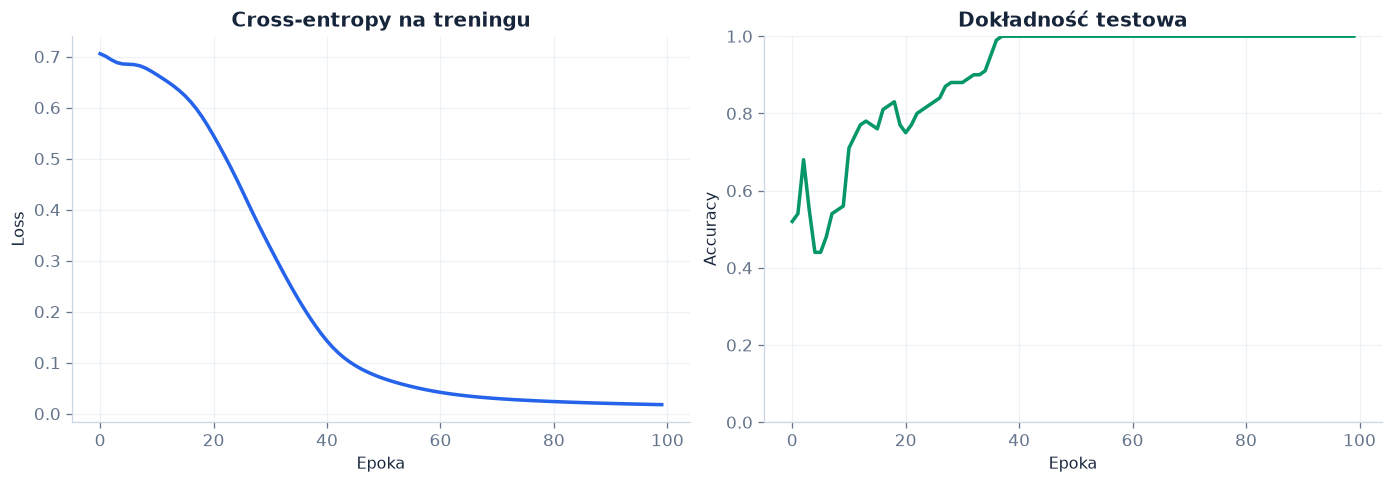

In [ ]:
perm = torch.randperm(n)
train_idx, test_idx = perm[:400], perm[400:]
X_train, y_train = X_t[train_idx], y_t[train_idx]
X_test, y_test = X_t[test_idx], y_t[test_idx]

net = CustomNetwork(2, 16, 2)
optimizer = torch.optim.SGD(net.parameters(), lr=0.22, momentum=0.9)
loss_history, acc_history = [], []
for epoch in range(100):
    net.train()
    optimizer.zero_grad()
    loss = F.cross_entropy(net(X_train), y_train)
    loss.backward()
    optimizer.step()
    net.eval()
    with torch.no_grad():
        test_acc = (net(X_test).argmax(1) == y_test).float().mean().item()
    loss_history.append(loss.item())
    acc_history.append(test_acc)
print(
    f"Po 100 epokach: loss(train)={loss_history[-1]:.3f}, accuracy(test)={acc_history[-1]:.1%}"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
axes[0].plot(loss_history, color=COL["blue"])
axes[0].set(title="Cross-entropy na treningu", xlabel="Epoka", ylabel="Loss")
axes[1].plot(acc_history, color=COL["green"])
axes[1].set(title="Dokładność testowa", xlabel="Epoka", ylabel="Accuracy", ylim=(0, 1))
for ax in axes:
    style_axes(ax)
plt.show()

**Co wynika z eksperymentu?** Sieć z nieliniową aktywacją może utworzyć nieliniową granicę decyzji. Nie jest to jednak teoretycznie zagwarantowane, a wynik zależy od parametrów treningu i inicjalizacji. Zauwa również, że krzywa dokładności może mieć płaskie fragmenty mimo malejącego `loss`.

**TensorFlow Playground:** [playground.tensorflow.org](https://playground.tensorflow.org/) — porównaj Gaussian, Circle i Spiral.

### Czym różni się optymalizator od funkcji straty?

Loss odpowiada na pytanie **jak bardzo myli się model?**, a optymalizator na pytanie **jak zmienić parametry na podstawie obliczonego gradientu?**. Tę samą stratę można minimalizować wieloma algorytmami. Ponieważ gradient bywa bardzo różny w różnych kierunkach, metoda aktualizacji wpływa na szybkość oraz stabilność ruchu.

- **Gradient Descent:** wykonuje krok przeciwny do gradientu. W wersji SGD gradient jest estymowany z pojedynczej próbki lub minibatcha; na naszym dwuwymiarowym przykładzie mamy pełny gradient.
- **Momentum:** przechowuje pamięć wcześniejszych gradientów. Przy naprzemiennych znakach w stromym kierunku ruchy częściowo się znoszą, a w stabilnym kierunku kumulują.
- **AdaGrad:** sumuje kwadraty historycznych gradientów **oddzielnie dla każdej współrzędnej**. Duże lub często spotykane gradienty prowadzą do mniejszego efektywnego kroku, ale akumulator stale rośnie.
- **RMSProp:** zastępuje sumę AdaGrad średnią wykładniczą, więc starsze gradienty stopniowo tracą znaczenie.
- **Adam:** wykorzystuje dwie średnie wykładnicze – gradientów ($m_t$) oraz ich kwadratów ($v_t$) – i koryguje ich początkowe obciążenie wynikające ze startu od zera.

## 3. Optymalizatory

Wszystkie optymalizatory widzą **gradient tej samej funkcji** i aktualizują parametry w różny sposób. Dla porównania wykorzystamy wypukłą, ale mocno wydłużoną powierzchnię:
$$L(w_1,w_2)=\tfrac12(w_1^2+20w_2^2).$$

Gradient $\nabla L=(w_1,20w_2)$ jest znacznie bardziej stromy w kierunku $w_2$. Stąd charakterystyczny zygzak zwykłego SGD. To nie jest model neuronowy, tylko kontrolowany przykład pozwalający *zobaczyć* mechanikę kolejnych algorytmów.

In [54]:
class Optimizer:
    def __init__(self, params):
        self.params = list(params)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()


class GradientDescent(Optimizer):
    def __init__(self, params, learning_rate=0.05):
        super().__init__(params)
        self.lr = learning_rate

    @torch.no_grad()
    def step(self):
        for p in self.params:
            p -= self.lr * p.grad


class Momentum(Optimizer):
    def __init__(self, params, learning_rate=0.05, gamma=0.9):
        super().__init__(params)
        self.lr, self.gamma = learning_rate, gamma
        self.velocity = [torch.zeros_like(p) for p in self.params]

    @torch.no_grad()
    def step(self):
        for p, v in zip(self.params, self.velocity):
            v.mul_(self.gamma).add_(p.grad, alpha=self.lr)
            p.sub_(v)


class Adagrad(Optimizer):
    def __init__(self, params, learning_rate=0.5, epsilon=1e-8):
        super().__init__(params)
        self.lr, self.eps = learning_rate, epsilon
        self.s = [torch.zeros_like(p) for p in self.params]

    @torch.no_grad()
    def step(self):
        for p, s in zip(self.params, self.s):
            s.add_(p.grad.square())
            p.sub_(self.lr * p.grad / torch.sqrt(s + self.eps))


class RMSProp(Optimizer):
    def __init__(self, params, learning_rate=0.1, gamma=0.9, epsilon=1e-8):
        super().__init__(params)
        self.lr, self.gamma, self.eps = learning_rate, gamma, epsilon
        self.s = [torch.zeros_like(p) for p in self.params]

    @torch.no_grad()
    def step(self):
        for p, s in zip(self.params, self.s):
            s.mul_(self.gamma).add_(p.grad.square(), alpha=1 - self.gamma)
            p.sub_(self.lr * p.grad / torch.sqrt(s + self.eps))


class Adam(Optimizer):
    def __init__(
        self, params, learning_rate=0.15, beta1=0.9, beta2=0.999, epsilon=1e-8
    ):
        super().__init__(params)
        self.lr, self.b1, self.b2, self.eps = learning_rate, beta1, beta2, epsilon
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0

    @torch.no_grad()
    def step(self):
        self.t += 1
        for p, m, v in zip(self.params, self.m, self.v):
            m.mul_(self.b1).add_(p.grad, alpha=1 - self.b1)
            v.mul_(self.b2).add_(p.grad.square(), alpha=1 - self.b2)
            mhat = m / (1 - self.b1**self.t)
            vhat = v / (1 - self.b2**self.t)
            p.sub_(self.lr * mhat / (vhat.sqrt() + self.eps))

### Reguły aktualizacji – co dokładnie zapamiętujemy?

Dla bieżącego gradientu $g_t=\nabla L(\theta_t)$ podstawowe reguły mają następującą postać (operacje i dzielenie wykonujemy elementowo):

**SGD:** $\theta_{t+1}=\theta_t-\eta g_t$.

**Momentum, wariant używany w kodzie:** $v_t=\gamma v_{t-1}+g_t$ i $\theta_{t+1}=\theta_t-\eta v_t$. W literaturze spotkasz również konwencję z czynnikiem $(1-\gamma)$; bez uwzględnienia tego czynnika wartości kroków nie są porównywalne.

**AdaGrad:** $s_t=s_{t-1}+g_t^2$ i $\theta_{t+1}=\theta_t-\eta g_t/(\sqrt{s_t}+\varepsilon)$ (dokładne położenie $\varepsilon$ zależy od implementacji).

**RMSProp:** $s_t=\gamma s_{t-1}+(1-\gamma)g_t^2$ i analogiczna aktualizacja ze skalowaniem przez pierwiastek ze średniej.

**Adam:** $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$, $\hat m_t=m_t/(1-\beta_1^t)$, $\hat v_t=v_t/(1-\beta_2^t)$; $\theta_{t+1}=\theta_t-\eta\hat m_t/(\sqrt{\hat v_t}+\varepsilon)$.

Pamiętaj, że **hiperparametry** (np. `learning_rate`, `gamma`, `beta1`, `beta2`) dobieramy osobno do metody i problemu. Różnice między krzywymi bez takiego strojenia nie są dowodem uniwersalnej przewagi jednego algorytmu.

### 3.1. Aktualizacja parametrów per optimiser

| Algorytm | Zapamiętywana informacja | Główna idea |
|---|---|---|
| Gradient Descent / SGD | brak dodatkowego stanu | Krok przeciwny do gradientu. Przy gradientach minibatch jest to SGD. |
| Momentum | $v_t$ — suma ważona wcześniejszych gradientów | Zmniejsza zygzakowanie i wzmacnia konsekwentny kierunek. |
| AdaGrad | $s_t=\sum_{k\le t}g_k^2$ | Dopasowuje krok do historii każdego parametru; krok może z czasem maleć. |
| RMSProp | $s_t=\gamma s_{t-1}+(1-\gamma)g_t^2$ | Używa wygaszanej pamięci kwadratów gradientów. |
| Adam | $m_t$ i $v_t$ | Łączy pamięć gradientu z adaptacją skali i korekcją obciążenia początkowego. |

**Uwaga:** `torch.optim.SGD` używa zwykle **stochastycznych/minibatchowych** gradientów; nasz `GradientDescent` na testowej funkcji korzysta z jej pełnego gradientu.

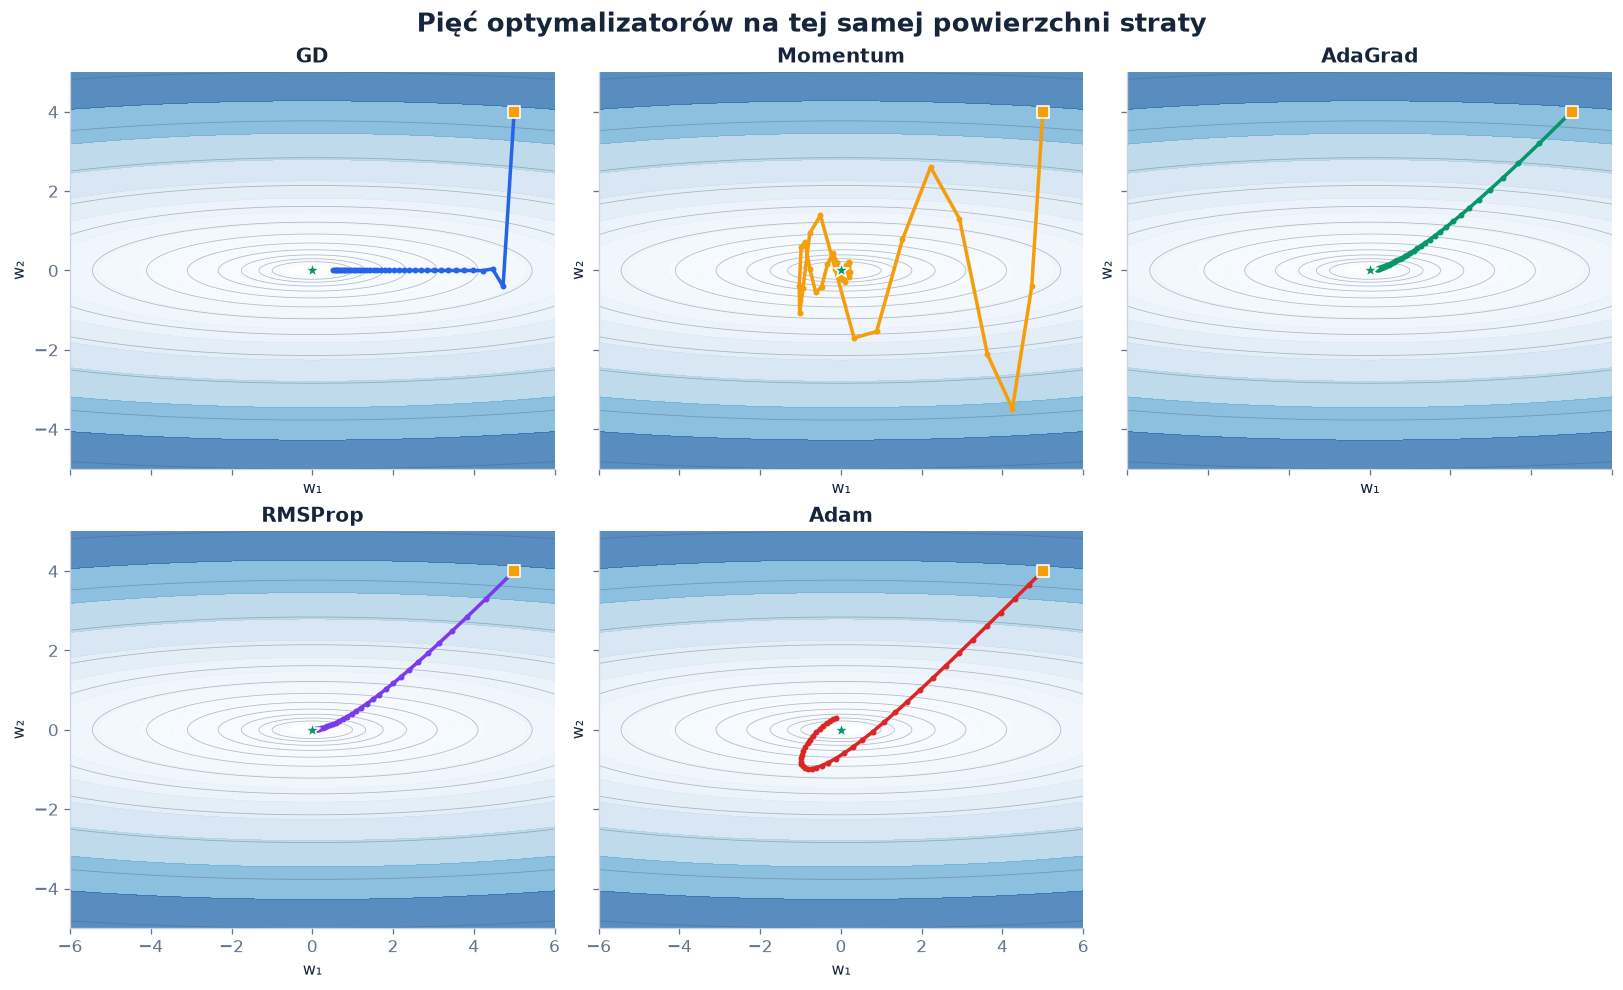

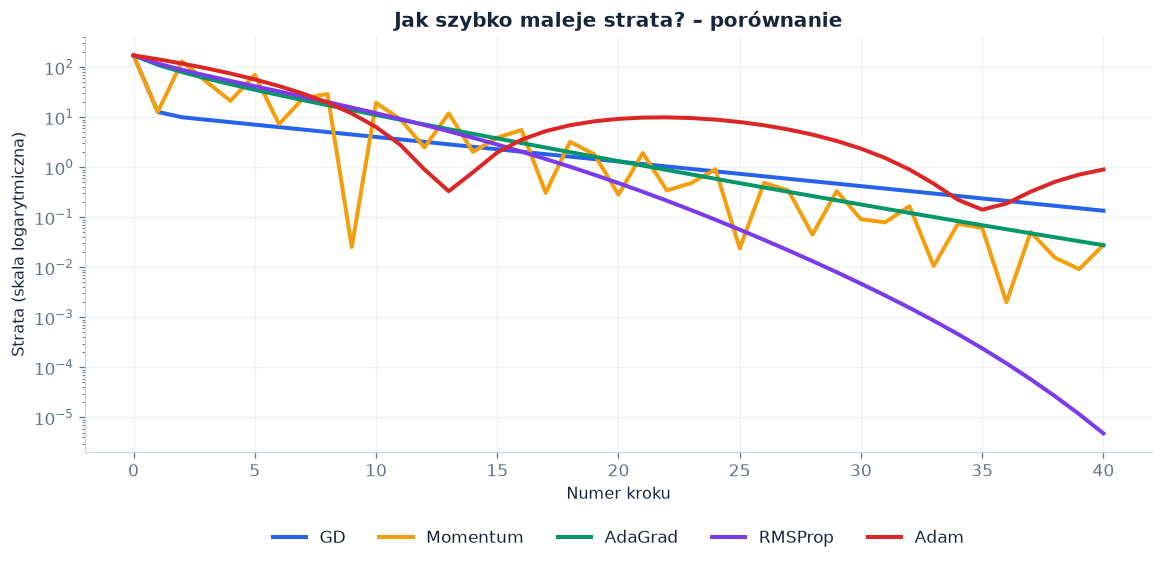

In [ ]:
def bowl(w):
    return 0.5 * (w[0] ** 2 + 20 * w[1] ** 2)


def trace_optimizer(cls, kwargs, start=(5.0, 4.0), steps=40):
    w = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = cls([w], **kwargs)
    path = [w.detach().numpy().copy()]
    losses = [bowl(w).item()]
    for _ in range(steps):
        opt.zero_grad()
        l = bowl(w)
        l.backward()
        opt.step()
        path.append(w.detach().numpy().copy())
        losses.append(bowl(w).item())
    return np.array(path), np.array(losses)


settings = {
    "GD": (GradientDescent, {"learning_rate": 0.055}),
    "Momentum": (Momentum, {"learning_rate": 0.055, "gamma": 0.8}),
    "AdaGrad": (Adagrad, {"learning_rate": 0.8}),
    "RMSProp": (RMSProp, {"learning_rate": 0.22}),
    "Adam": (Adam, {"learning_rate": 0.35}),
}
traces = {
    name: trace_optimizer(cls, kwargs) for name, (cls, kwargs) in settings.items()
}
# Każda metoda na tej samej geometrii; układ paneli pozwala porównywać ruch.
a = np.linspace(-6, 6, 180)
b = np.linspace(-5, 5, 180)
AA, BB = np.meshgrid(a, b)
fig, axes = plt.subplots(
    2, 3, figsize=(14, 8.5), sharex=True, sharey=True, layout="constrained"
)
for ax, (name, (path, losses)) in zip(axes.flat, traces.items()):
    ax.contourf(
        AA,
        BB,
        0.5 * (AA**2 + 20 * BB**2),
        levels=np.geomspace(0.2, 280, 18),
        cmap="Blues",
        alpha=0.7,
        extend="max",
    )
    ax.contour(
        AA,
        BB,
        0.5 * (AA**2 + 20 * BB**2),
        levels=np.geomspace(0.5, 250, 12),
        colors="#475569",
        linewidths=0.5,
        alpha=0.38,
    )
    ax.plot(path[:, 0], path[:, 1], "o-", ms=2.7, lw=2.2, color=OPT_COL[name])
    ax.scatter(
        path[0, 0],
        path[0, 1],
        s=60,
        marker="s",
        color=COL["orange"],
        edgecolors="white",
        zorder=5,
    )
    ax.scatter(0, 0, marker="*", s=100, c=COL["green"], edgecolors="white", zorder=5)
    ax.set_title(name)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-5, 5)
    ax.set_xlabel("w₁")
    ax.set_ylabel("w₂")
axes.flat[-1].axis("off")
fig.suptitle(
    "Pięć optymalizatorów na tej samej powierzchni straty",
    fontsize=16,
    fontweight="bold",
)
plt.show()
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
for name, (path, losses) in traces.items():
    ax.semilogy(
        np.maximum(losses, 1e-12), label=name, color=OPT_COL[name], linewidth=2.5
    )
ax.set(
    xlabel="Numer kroku",
    ylabel="Strata (skala logarytmiczna)",
    title="Jak szybko maleje strata? – porównanie",
)
style_axes(ax)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()

**Co zobaczyliśmy?** GD jest wrażliwy na relację learning rate do krzywizny. Momentum „pamięta” poprzednie kroki. AdaGrad zmniejsza efektywny learning rate w wymiarach z dużymi gradientami. RMSProp i Adam wygaszają wpływ dawnych gradientów. **Nie porównujemy algorytmów „kto jest najlepszy” bez strojenia:** tutaj każdy ma osobny learning rate dobrany demonstracyjnie do pojedynczego problemu.

### 3.2. Co robi korekcja biasu w Adam?

Jeśli $m_0=v_0=0$, pierwsze wykładnicze średnie są początkowo obciążone ku zeru. Adam stosuje $\hat m_t=m_t/(1-\beta_1^t)$ i $\hat v_t=v_t/(1-\beta_2^t)$. Porównajmy pierwszy krok przy stałym gradiencie.

In [56]:
gradient = torch.tensor([2.0, 8.0])
b1, b2 = 0.9, 0.999
m1 = (1 - b1) * gradient
v1 = (1 - b2) * gradient**2
print("m bez korekcji:", m1.tolist())
print("m skorygowane:", (m1 / (1 - b1)).tolist())
print("v skorygowane:", (v1 / (1 - b2)).tolist())
print(
    "Adam: kierunek kroku po skorygowaniu ≈",
    (m1 / (1 - b1) / ((v1 / (1 - b2)).sqrt() + 1e-8)).tolist(),
)

m bez korekcji: [0.20000000298023224, 0.800000011920929]
m skorygowane: [2.0, 8.0]
v skorygowane: [4.0, 64.0]
Adam: kierunek kroku po skorygowaniu ≈ [1.0, 1.0]


### 3.3. Czy nasze implementacje aktualizują parametry jak PyTorch?

Porównujemy pojedynczy krok na dokładnie tym samym gradiencie. To kontrola *reguły aktualizacji*, a nie wynik treningu. Dla `Adam` stosujemy epsilon **poza** pierwiastkiem; tak samo jest w `torch.optim.Adam`. Oryginalna implementacja AdaGrad i RMSProp dodaje epsilon wewnątrz pierwiastka, w tej formie pozostawiliśmy je również tutaj.

In [57]:
comparison = [
    ("GD", GradientDescent, {"learning_rate": 0.05}, torch.optim.SGD, {"lr": 0.05}),
    (
        "Momentum",
        Momentum,
        {"learning_rate": 0.05, "gamma": 0.9},
        torch.optim.SGD,
        {"lr": 0.05, "momentum": 0.9},
    ),
    ("Adam", Adam, {"learning_rate": 0.01}, torch.optim.Adam, {"lr": 0.01}),
]
for name, own_cls, own_args, lib_cls, lib_args in comparison:
    p = torch.tensor([1.0, -2.0], requires_grad=True)
    q = torch.tensor([1.0, -2.0], requires_grad=True)
    own = own_cls([p], **own_args)
    lib = lib_cls([q], **lib_args)
    bowl(p).backward()
    bowl(q).backward()
    own.step()
    lib.step()
    print(name, "maksymalna różnica po 1 kroku:", (p - q).abs().max().item())

GD maksymalna różnica po 1 kroku: 2.9802322387695312e-08
Momentum maksymalna różnica po 1 kroku: 2.9802322387695312e-08
Adam maksymalna różnica po 1 kroku: 0.0


### Uczciwe porównanie sposobów trenowania

Aby porównywać metody optymalizacji, trzeba zachować te same dane, architekturę, funkcję straty, podział train/test i początkowe wagi. Inaczej widoczna różnica może wynikać z przypadkowej inicjalizacji, a nie z reguły aktualizacji. Nawet w kontrolowanym przykładzie nie uzyskamy wiarygodnego **rankingu algorytmów** bez sprawdzenia kilku learning rate i losowych ziaren.

W praktyce wybór to układ **model + loss + optymalizator + sposób ewaluacji**. Każdy z tych elementów odpowiada na inne pytanie i może prowadzić do innej diagnozy błędów.

## 4. Podsumowanie

Projektując proces treningu podejmujemy następujące decyzje:

1. **Model:** jaką rodzinę funkcji możemy reprezentować?
2. **Funkcja straty:** co ma być karane?
3. **Optymalizator:** jak zmieniać parametry, żeby obniżyć stratę?
4. **Metryka:** po czym oceniamy jakość na danych niewidzianych podczas treningu?

Dla sieci klasyfikacyjnej możemy użyć `nn.CrossEntropyLoss` i dowolnego z `torch.optim` bez zmiany architektury. Dla sprawiedliwszego porównania ustawiamy identyczną inicjalizację oraz te same dane. Różne metody wymagają często różnych learning rate (poniższy eksperyment jest ilustracją, nie rankingiem).

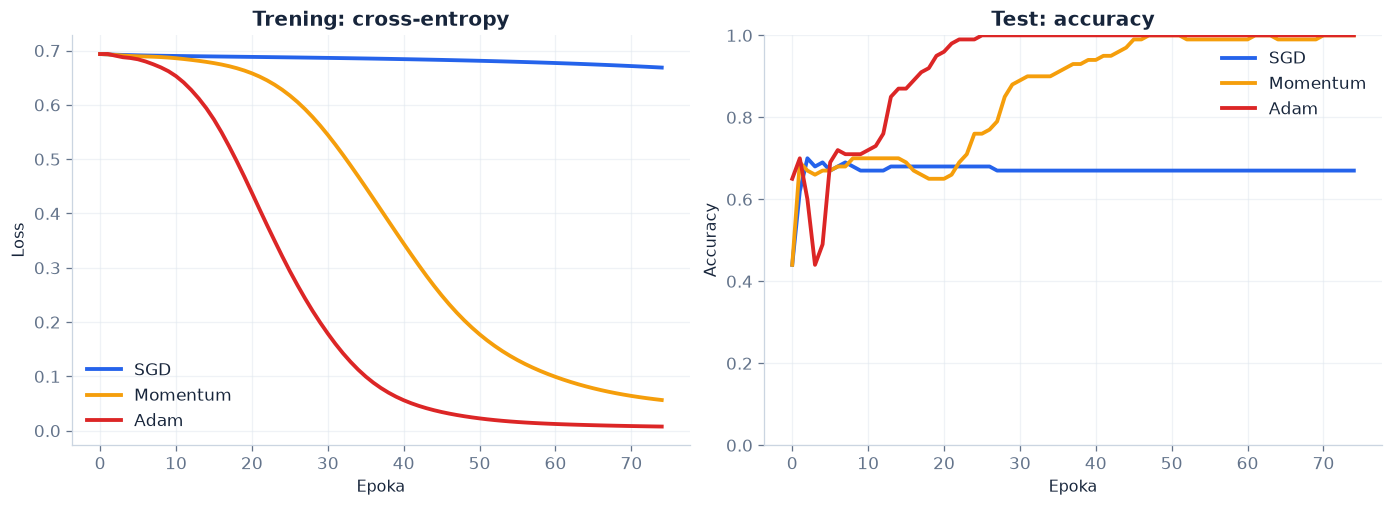

In [ ]:
import copy

base = CustomNetwork(2, 16, 2)
start_state = copy.deepcopy(base.state_dict())
configs = {
    "SGD": (torch.optim.SGD, {"lr": 0.2}),
    "Momentum": (torch.optim.SGD, {"lr": 0.2, "momentum": 0.9}),
    "Adam": (torch.optim.Adam, {"lr": 0.03}),
}
records = {}
for name, (cls, kwargs) in configs.items():
    network = CustomNetwork(2, 16, 2)
    network.load_state_dict(start_state)
    opt = cls(network.parameters(), **kwargs)
    train_losses = []
    test_accuracies = []
    for epoch in range(75):
        opt.zero_grad()
        l = F.cross_entropy(network(X_train), y_train)
        l.backward()
        opt.step()
        with torch.no_grad():
            acc = (network(X_test).argmax(1) == y_test).float().mean().item()
        train_losses.append(l.item())
        test_accuracies.append(acc)
    records[name] = (train_losses, test_accuracies)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
for name, (losses, acc) in records.items():
    axes[0].plot(losses, label=name, color=OPT_COL[name], lw=2.4)
    axes[1].plot(acc, label=name, color=OPT_COL[name], lw=2.4)
axes[0].set(title="Trening: cross-entropy", xlabel="Epoka", ylabel="Loss")
axes[1].set(title="Test: accuracy", xlabel="Epoka", ylabel="Accuracy", ylim=(0, 1))
for ax in axes:
    ax.legend()
    style_axes(ax)
plt.show()

* **Ta sama próbka, różne funkcje straty:** dla punktów w 1D średnia, mediana i środek rozpiętości mogą dać odmienne rozwiązania; obserwacje odstające uwypuklają różnicę.
* **Gradient descent:** przy tej samej funkcji może działać szybko, wolno lub niestabilnie, zależnie od długości kroku i krzywizny.
* **Sieć neuronowa:** nieliniowość warstw poszerza klasę reprezentowanych funkcji; `CrossEntropyLoss` operuje na logitach, a `backward()` oblicza gradient wszystkich parametrów z reguły łańcuchowej.
* **Optymalizatory:** Momentum wprowadza pamięć kierunku; AdaGrad i RMSProp adaptują skalę kroku; Adam łączy oba pomysły i koryguje początkowe obciążenie średnich.
* **Ewaluacja:** zmniejszanie funkcji straty treningowej nie jest automatycznie gwarancją lepszego accuracy na teście.